# Course 14: AI Research in 2026
## Session 8: Grokking, proved

**Goal:** reproduce grokking in over-parameterized ridge regression, predict the grokking time with one line of algebra, and show how weight decay, learning rate and initialization stretch or remove it.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### The 2026 paper
Xu, Vardi and Safran, *To Grok Grokking: Provable Grokking in Ridge Regression* (ICML 2026, Outstanding Paper Honorable Mention). They prove that gradient descent with weight decay on over-parameterized linear regression first overfits, keeps generalizing poorly long after that, and finally generalizes. They bound the delay, the "grokking time", in terms of the training hyperparameters, and show it can be amplified or removed by tuning them.

This lab is a toy illustration, not a reproduction. Our setting is of the kind the paper studies (Gaussian inputs, a linear teacher, thresholds on the training and test loss), but the formula we use to predict the grokking time is a one-line calculation for this toy, not the paper's theorem, whose exact statement and constants we have not checked. The random-features part in section 6 is an experiment only, as in the paper.

### 1. Teacher, student and data
Inputs $x \sim N(0, I_d/d)$ with $d = 400$, only $n = 100$ training points, and a teacher $y = w_*^T x$ with $\|w_*\| = 1$ and no noise. The student is a linear model $w \in \mathbb{R}^{400}$: four times more parameters than equations. We minimize $\frac{1}{2n}\|Xw - y\|^2 + \frac{\lambda}{2}\|w\|^2$ by plain gradient descent. Because the inputs are isotropic, the test loss is exactly $\|w - w_*\|^2/d$, so we never need a test set.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
rng = np.random.default_rng(0)
d, n, eps = 400, 100, 0.01                    # eps: the loss threshold that defines "fitted" and "generalized"
X = rng.standard_normal((n, d)) / np.sqrt(d)
w_star = rng.standard_normal(d)
w_star /= np.linalg.norm(w_star)
y = X @ w_star

H = X.T @ X / n
eig = np.linalg.eigvalsh(H)
print(f"nonzero eigenvalues of X^T X / n: {np.sum(eig > 1e-10)} of {d}, from {eig[eig > 1e-10].min():.4f} to {eig.max():.4f}")

nonzero eigenvalues of X^T X / n: 100 of 400, from 0.0028 to 0.0223


### 2. Grokking in a linear model
Start from a large random initialization, $w_0 \sim N(0, \nu^2 I)$ with $\nu = 1$, and train with learning rate $\eta = 1$ and weight decay $\lambda = 2 \times 10^{-4}$. We record $t_1$, the first step with training loss below 0.01, and $t_2$, the first step with test loss below 0.01. The grokking delay is $t_2 - t_1$.

t1 (training loss <= 0.01): step 265    t2 (test loss <= 0.01): step 10859    delay ratio t2/t1 = 41
at step 265: training loss 0.0099, test loss 0.582
(1.1 s)


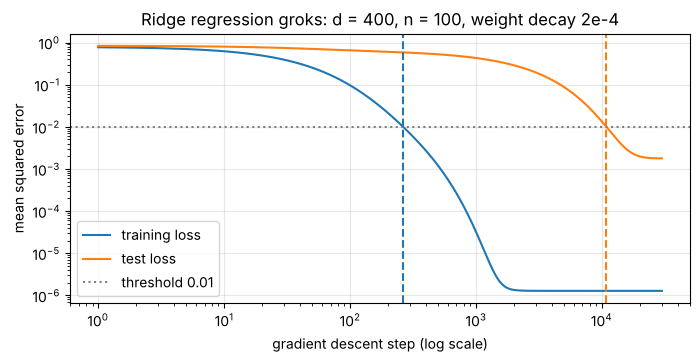

In [2]:
def train_gd(lam, eta=1.0, nu=1.0, max_steps=60000, seed=1, record=False):
    w = nu * np.random.default_rng(seed).standard_normal(d)
    t1 = t2 = None
    hist = []
    for t in range(1, max_steps + 1):
        r = X @ w - y
        w = w - eta * (X.T @ r / n + lam * w)
        train_loss = np.mean((X @ w - y) ** 2)
        test_loss = np.sum((w - w_star) ** 2) / d
        if record:
            hist.append((train_loss, test_loss))
        if t1 is None and train_loss <= eps:
            t1 = t
        if t2 is None and test_loss <= eps:
            t2 = t
        if t1 and t2 and not record:
            break
    return t1, t2, np.array(hist)

t0 = time.time()
t1, t2, hist = train_gd(lam=2e-4, max_steps=30000, record=True)
print(f"t1 (training loss <= 0.01): step {t1}    t2 (test loss <= 0.01): step {t2}    delay ratio t2/t1 = {t2 / t1:.0f}")
print(f"at step {t1}: training loss {hist[t1 - 1, 0]:.4f}, test loss {hist[t1 - 1, 1]:.3f}")
print(f"({time.time() - t0:.1f} s)")

steps = np.arange(1, len(hist) + 1)
plt.figure(figsize=(8, 3.5))
plt.loglog(steps, hist[:, 0], label="training loss")
plt.loglog(steps, hist[:, 1], label="test loss")
plt.axhline(eps, color="gray", ls=":", label="threshold 0.01")
plt.axvline(t1, color="C0", ls="--"); plt.axvline(t2, color="C1", ls="--")
plt.xlabel("gradient descent step (log scale)"); plt.ylabel("mean squared error")
plt.title("Ridge regression groks: d = 400, n = 100, weight decay 2e-4")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 3. Why: the part of $w$ the data cannot see
Split $w = w_\parallel + w_\perp$, where $w_\parallel$ lies in the span of the 100 training inputs and $w_\perp$ is orthogonal to all of them. The data gradient $X^T(Xw - y)/n$ lies in the span, so it never touches $w_\perp$. Only weight decay does:

$w_\perp(t) = (1 - \eta\lambda)^t\, w_\perp(0)$.

$w_\parallel$ settles fast, so the training loss falls first. But the test loss contains $\|w_\perp\|^2/d$, which is large after a large initialization and shrinks only by the factor $(1 - \eta\lambda)^2$ per step. Setting $\|w_\perp(t)\|^2/d$ equal to the room left under the threshold gives a prediction:

$t_2 \approx \dfrac{\ln\big(\|w_\perp(0)\|^2 / (d\,(\varepsilon - L_\infty))\big)}{-2\ln(1 - \eta\lambda)}$, where $L_\infty$ is the test loss of the final (ridge) solution.

In [3]:
_, _, Vt = np.linalg.svd(X, full_matrices=False)
P_par = Vt.T @ Vt                                   # projector onto the span of the training inputs
P_perp = np.eye(d) - P_par

def predict_t2(lam, eta=1.0, nu=1.0, seed=1):
    w0 = nu * np.random.default_rng(seed).standard_normal(d)
    perp0 = np.sum((P_perp @ w0) ** 2) / d          # test loss contributed by w_perp at the start
    w_ridge = np.linalg.solve(H + lam * np.eye(d), X.T @ y / n)
    L_inf = np.sum((w_ridge - w_star) ** 2) / d     # test loss of the final solution
    if perp0 <= eps - L_inf:
        return 0.0, perp0, L_inf
    return np.log(perp0 / (eps - L_inf)) / (-2 * np.log(1 - eta * lam)), perp0, L_inf

# check the decay law on the run from section 2: recompute w at step 5,000 and look at its perpendicular part
w = np.random.default_rng(1).standard_normal(d)
w_perp0 = np.linalg.norm(P_perp @ w)
for t in range(5000):
    w = w - 1.0 * (X.T @ (X @ w - y) / n + 2e-4 * w)
print(f"||w_perp|| at step 5,000: {np.linalg.norm(P_perp @ w):.4f}    (1 - eta*lambda)^5000 * ||w_perp(0)|| = {(1 - 2e-4) ** 5000 * w_perp0:.4f}")

pred, perp0, L_inf = predict_t2(2e-4)
print(f"test loss from w_perp at the start: {perp0:.3f}    final test loss L_inf: {L_inf:.4f}")
print(f"predicted t2: {pred:.0f}    measured t2: {t2}")

||w_perp|| at step 5,000: 5.8826    (1 - eta*lambda)^5000 * ||w_perp(0)|| = 5.8826
test loss from w_perp at the start: 0.639    final test loss L_inf: 0.0018
predicted t2: 10885    measured t2: 10859


### 4. Stretching and removing grokking
Change one hyperparameter at a time, starting from $\lambda = 2\times10^{-4}$, $\eta = 1$, $\nu = 1$. The calculation in section 3 says: $t_2$ grows like $1/(\eta\lambda)$, grows only like $\ln \nu$ with the initialization scale, and disappears when the initial $w_\perp$ is already small. $t_1$ does not depend much on $\lambda$, so the ratio $t_2/t_1$ is set mostly by $\lambda$.

changed          lambda   eta    nu     t1      t2   t2/t1  predicted t2


weight decay      1e-04  1.00   1.0    270   21718    80.4         21770


weight decay      2e-04  1.00   1.0    265   10859    41.0         10885


weight decay      5e-04  1.00   1.0    251    4343    17.3          4353


weight decay      1e-03  1.00   1.0    232    2172     9.4          2177


weight decay      2e-03  1.00   1.0    203    1086     5.3          1088


... (4 outputs left out)

init scale        2e-04  1.00   3.0    510   16351    32.1         16377


init scale        2e-04  1.00  10.0    833   22371    26.9         22396


learning rate     2e-04  0.25   1.0   1059   43437    41.0         43541


learning rate     2e-04  0.50   1.0    530   21718    41.0         21770
(18 s)


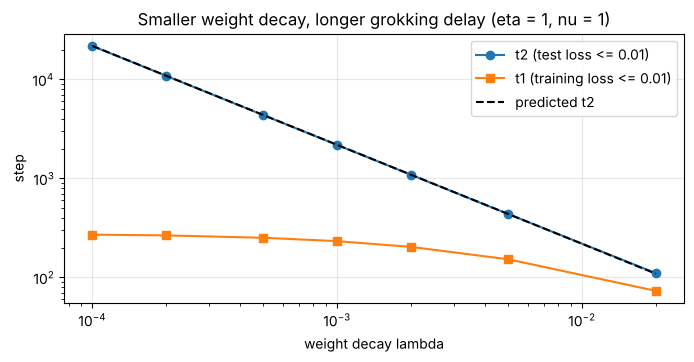

In [4]:
t0 = time.time()
rows = []
for lam in [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3, 2e-2]:
    rows.append(("weight decay", lam, 1.0, 1.0))
for nu in [0.1, 0.3, 3.0, 10.0]:
    rows.append(("init scale", 2e-4, 1.0, nu))
for eta in [0.25, 0.5]:
    rows.append(("learning rate", 2e-4, eta, 1.0))
print(f"{'changed':14s} {'lambda':>8s} {'eta':>5s} {'nu':>5s} {'t1':>6s} {'t2':>7s} {'t2/t1':>7s} {'predicted t2':>13s}")
sweep = []
for what, lam, eta, nu in rows:
    t1_, t2_, _ = train_gd(lam, eta=eta, nu=nu)
    pred_, _, _ = predict_t2(lam, eta=eta, nu=nu)
    sweep.append((what, lam, eta, nu, t1_, t2_))
    print(f"{what:14s} {lam:8.0e} {eta:5.2f} {nu:5.1f} {t1_:6d} {t2_:7d} {t2_ / t1_:7.1f} {pred_:13.0f}")
print(f"({time.time() - t0:.0f} s)")

lam_rows = [r for r in sweep if r[0] == "weight decay"]
lams = np.array([r[1] for r in lam_rows])
plt.figure(figsize=(8, 3.5))
plt.loglog(lams, [r[5] for r in lam_rows], "o-", label="t2 (test loss <= 0.01)")
plt.loglog(lams, [r[4] for r in lam_rows], "s-", label="t1 (training loss <= 0.01)")
plt.loglog(lams, [predict_t2(l)[0] for l in lams], "k--", label="predicted t2")
plt.xlabel("weight decay lambda"); plt.ylabel("step")
plt.title("Smaller weight decay, longer grokking delay (eta = 1, nu = 1)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 5. Beyond linear: random ReLU features
The paper's proofs cover the linear case; its experiments show the same behaviour qualitatively in random-feature models and two-layer networks. Here the inputs are $z \in \mathbb{R}^{20}$, the student sees 500 fixed random ReLU features $\phi(z)$, and the teacher is another random-features model, $y = a_*^T\phi(z)$ with $\|a_*\| = 1$, so the student can fit it exactly. Only the output weights $a$ are trained, with gradient descent and weight decay from a large initialization. The test loss is computed on 4,000 fresh inputs.

weight decay    t1      t2    t2/t1   t2 x lambda


     1e-04     915   11550    12.6        1.16
     3e-04     745    3905     5.2        1.17
     1e-03     475    1235     2.6        1.24


(1 s; t1 and t2 are checked every 5 steps)


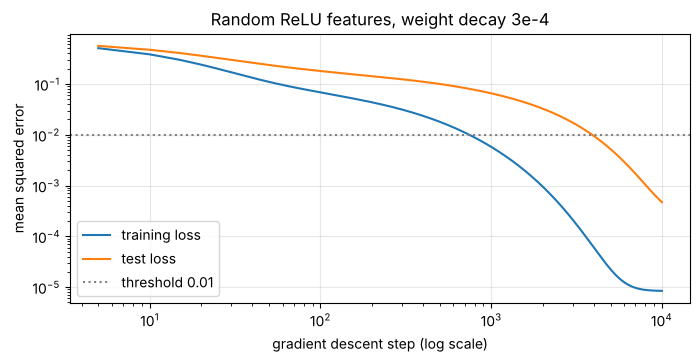

In [5]:
rf = np.random.default_rng(3)
d0, p, n_rf = 20, 500, 100
W_rf = rf.standard_normal((p, d0)) / np.sqrt(d0)
features = lambda Z: np.sqrt(2.0 / p) * np.maximum(Z @ W_rf.T, 0.0)
F_tr = features(rf.standard_normal((n_rf, d0)))
F_te = features(rf.standard_normal((4000, d0)))
Sigma_te = F_te.T @ F_te / len(F_te)                  # test loss = (a - a*)^T Sigma (a - a*)
a_star = rf.standard_normal(p)
a_star /= np.linalg.norm(a_star)
y_rf = F_tr @ a_star

def train_rf(lam, nu=1.0, max_steps=40000, record=False):
    a = nu * np.random.default_rng(5).standard_normal(p)
    t1 = t2 = None
    hist = []
    for t in range(1, max_steps + 1):
        a = a - (F_tr.T @ (F_tr @ a - y_rf) / n_rf + lam * a)
        if t % 5 == 0:                                 # check both losses every 5 steps to keep this fast
            tr = np.mean((F_tr @ a - y_rf) ** 2)
            e = a - a_star
            te = e @ Sigma_te @ e
            if record:
                hist.append((t, tr, te))
            if t1 is None and tr <= eps:
                t1 = t
            if t2 is None and te <= eps:
                t2 = t
            if t1 and t2 and not record:
                break
    return t1, t2, np.array(hist)

t0 = time.time()
print("weight decay    t1      t2    t2/t1   t2 x lambda")
for lam in [1e-4, 3e-4, 1e-3]:
    t1_, t2_, _ = train_rf(lam)
    print(f"{lam:10.0e} {t1_:7d} {t2_:7d} {t2_ / t1_:7.1f} {t2_ * lam:11.2f}")
_, _, h = train_rf(3e-4, max_steps=10000, record=True)
print(f"({time.time() - t0:.0f} s; t1 and t2 are checked every 5 steps)")

plt.figure(figsize=(8, 3.5))
plt.loglog(h[:, 0], h[:, 1], label="training loss")
plt.loglog(h[:, 0], h[:, 2], label="test loss")
plt.axhline(eps, color="gray", ls=":", label="threshold 0.01")
plt.xlabel("gradient descent step (log scale)"); plt.ylabel("mean squared error")
plt.title("Random ReLU features, weight decay 3e-4")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 6. The authors' code (NOT RUN here)
The paper's experiments (ridge regression, random features, NTK-style and fully trained ReLU networks) are in a public repository.

In [ ]:
# NOT RUN: needs internet access (to clone the authors' repository)
!git clone https://github.com/raymondmyxu/to-grok-grokking
# Read its README for the commands that run the ridge-regression and random-feature sweeps,
# then compare their measured t1 and t2 with the numbers from section 4 of this notebook.

### TODO
1. Add label noise: `y = X @ w_star + 0.05 * noise`. The final test loss rises; does the 1/λ law for $t_2$ survive if you raise the threshold above the new floor?
2. Replace gradient descent with full-batch AdamW (decoupled weight decay) in section 2. Is there still a delay, and does it still scale like $1/\lambda$?

In [6]:
# TODO: AdamW version of train_gd; return (t1, t2) like train_gd does
def train_adamw(lam, lr=1e-2, nu=1.0, max_steps=20000):
    return None          # replace: use torch.optim.AdamW on a torch copy of w, full batch

result = train_adamw(2e-4)
print("not done yet" if result is None else f"AdamW: t1 = {result[0]}, t2 = {result[1]}")

not done yet


### What to notice
- **A linear model groks.** With 400 parameters, 100 training points, weight decay 2e-4 and a large initialization, the training loss fell below 0.01 at step 265, when the test loss was still 0.582. The test loss crossed 0.01 only at step 10,859, 41 times later.
- **The mechanism is visible.** The part of $w$ orthogonal to the training inputs decayed exactly as $(1-\eta\lambda)^t$ (5.8826 measured and predicted at step 5,000). The one-line prediction gave $t_2$ = 10,885 against 10,859 measured. It stayed within 1% everywhere in the sweep where there was a delay, and it predicted no delay for ν = 0.1.
- **Weight decay sets the delay.** $t_2$ went from 21,718 steps at λ = 1e-4 to 110 at λ = 0.02, almost exactly in proportion to 1/λ, while $t_1$ only moved from 270 to 73. Large weight decay removed grokking ($t_2/t_1$ = 1.5).
- **The initialization scale enters through a logarithm.** Raising ν from 1 to 10 added about 11,500 steps to $t_2$ (10,859 to 22,371) instead of multiplying it. A small initialization (ν = 0.1) removed grokking ($t_1$ = 4, $t_2$ = 16).
- **The learning rate only changes the clock.** Halving η doubled both $t_1$ and $t_2$; $t_2/t_1$ stayed at 41.0.
- **Random ReLU features behave the same way, less sharply.** $t_2 \times \lambda$ stayed between 1.16 and 1.24, so the 1/λ pattern held, but the delay ratio was smaller (12.6 at λ = 1e-4) and $t_1$ also depended on λ, because some feature directions are fitted slowly.
- **Against intuition:** a larger initialization lengthened the delay $t_2 - t_1$ but lowered the ratio $t_2/t_1$ (50.9 at ν = 0.3, 26.9 at ν = 10), because $t_1$ grows too. Always say which measure of delay you use.